Lowest vibrational energy: -0.154 eV (-1.54e-07 MeV)


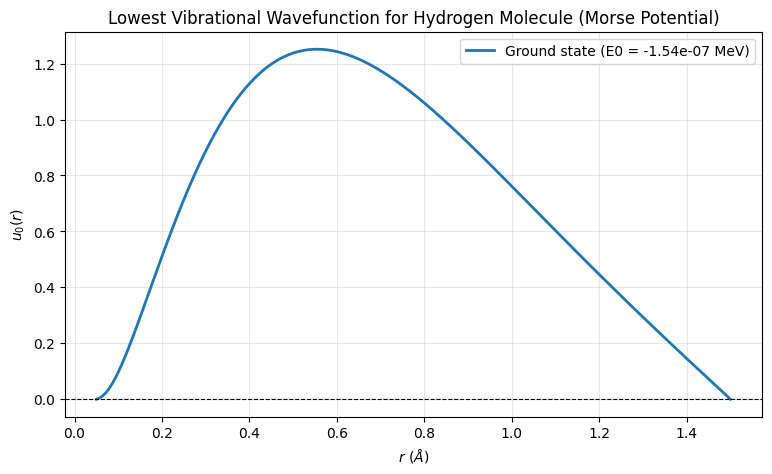

In [1]:
import numpy as np
import matplotlib.pyplot as plt

hbar_c = 1973.0
m = 940e6
D = 0.755501
alpha = 1.44
r0 = 0.131349

def morse_potential(r):
    r_prime = (r - r0) / r
    return D * (np.exp(-2.0 * alpha * r_prime) - np.exp(-alpha * r_prime))

def build_hamiltonian(dr, V):
    n = len(V)
    coeff = (hbar_c**2) / (2.0 * m * (dr**2))
    main_diag = 2.0 * coeff + V
    off_diag = np.full(n - 1, -coeff)
    return np.diag(main_diag) + np.diag(off_diag, 1) + np.diag(off_diag, -1)

r_min = 0.05
r_max = 1.5
N = 1000

dr = (r_max - r_min) / (N + 1)
r_int = r_min + dr * np.arange(1, N + 1)
V_int = morse_potential(r_int)

H = build_hamiltonian(dr, V_int)
evals, evecs = np.linalg.eigh(H)

E0_eV = evals[0]
E0_MeV = E0_eV * 1e-6

psi0_int = evecs[:, 0]
if np.max(psi0_int) < abs(np.min(psi0_int)):
    psi0_int = -psi0_int

r_full = np.concatenate(([r_min], r_int, [r_max]))
psi0 = np.concatenate(([0.0], psi0_int, [0.0]))
norm = np.sqrt(np.sum(np.abs(psi0)**2) * dr)
psi0_norm = psi0 / norm

print(f"Lowest vibrational energy: {E0_eV:.3g} eV ({E0_MeV:.3g} MeV)")

plt.figure(figsize=(9, 5))
plt.plot(r_full, psi0_norm, label=f"Ground state (E0 = {E0_MeV:.3g} MeV)", linewidth=2)
plt.axhline(0, color="black", linewidth=0.8, linestyle="--")
plt.xlabel(r"$r$ ($\AA$)")
plt.ylabel(r"$u_0(r)$")
plt.title("Lowest Vibrational Wavefunction for Hydrogen Molecule (Morse Potential)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()